In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TRAVELIQ - Data Exploration")

TRAVELIQ - Data Exploration


In [2]:
from pathlib import Path

# Find the project root
PROJECT_ROOT = Path.cwd().parent

# Load cleaned GeoNames data
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "geonames_cities_clean.csv"

cities = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Rows: {len(cities):,}")
print(f"Columns: {len(cities.columns)}")

Dataset loaded successfully!
Rows: 235,876
Columns: 9


In [3]:
cities.head()

,geoname_id,city,city_ascii,latitude,longitude,country_code,region_code,population,timezone
0,3041604,Aixirivall,Aixirivall,42.46245,1.50209,AD,06,1041,Europe/Andorra
1,3041563,Andorra la Vella,Andorra la Vella,42.50779,1.52109,AD,07,20430,Europe/Andorra
2,3041543,Anyós,Anyos,42.53465,1.52510,AD,04,1006,Europe/Andorra
3,3041519,Arinsal,Arinsal,42.57205,1.48453,AD,04,1419,Europe/Andorra
4,3041204,Canillo,Canillo,42.56760,1.59756,AD,02,3292,Europe/Andorra


In [4]:
print(f"Number of countries: {cities['country_code'].nunique()}")

Number of countries: 245


In [5]:
cities["country_code"].value_counts().head(20)

country_code
US    21785
MX    16880
CN    16055
FR    15364
DE    11921
IT    11855
ID     9307
ES     7422
IN     7166
RO     7149
GB     5919
BR     5898
UA     5581
RU     5323
CI     5136
AU     4902
PH     4529
TR     4035
PL     3869
CA     3303
Name: count, dtype: int64

In [6]:
india = cities[cities["country_code"] == "IN"].copy()

print(f"Indian cities in dataset: {len(india):,}")

Indian cities in dataset: 7,166


In [7]:
india.sort_values(
    by="population",
    ascending=False
)[
    [
        "city",
        "region_code",
        "latitude",
        "longitude",
        "population"
    ]
].head(30)

,city,region_code,latitude,longitude,population
119100,Mumbai,16,19.07283,72.88261,12691836
116451,Delhi,07,28.65195,77.23149,11034555
115571,Bengaluru,19,12.97194,77.59369,8495492
117234,Hyderabad,40,17.38405,78.45636,6993262
114928,Ahmedabad,09,23.02579,72.58727,6357693
116138,Chennai,25,13.08784,80.27847,4681087
118093,Kolkata,28,22.56263,88.36304,4631392
121106,Surat,09,21.19594,72.83023,4591246
120105,Pune,16,18.51957,73.85535,3124458
117357,Jaipur,24,26.91962,75.78781,3046163


In [8]:
places_to_check = [
    "Pune",
    "Mumbai",
    "Delhi",
    "Bengaluru",
    "Goa",
    "Jaipur",
    "Kochi",
    "Srinagar",
    "Manali",
    "Hampi"
]

for place in places_to_check:
    matches = cities[
        cities["city"].str.contains(
            place,
            case=False,
            na=False
        )
    ]

    print(f"\n{place}: {len(matches)} match(es)")
    print(matches[["city", "country_code", "latitude", "longitude"]].head(5))


Pune: 1 match(es)
        city country_code  latitude  longitude
120105  Pune           IN  18.51957   73.85535

Mumbai: 2 match(es)
               city country_code  latitude  longitude
119100       Mumbai           IN  19.07283   72.88261
119422  Navi Mumbai           IN  19.03681   73.01582

Delhi: 8 match(es)
                    city country_code  latitude  longitude
22502              Delhi           CA  42.85010  -80.49968
116451             Delhi           IN  28.65195   77.23149
116452  Delhi Cantonment           IN  28.60000   77.13333
119473         New Delhi           IN  28.62137   77.21480
215480             Delhi           US  32.45764  -91.49317

Bengaluru: 1 match(es)
             city country_code  latitude  longitude
115571  Bengaluru           IN  12.97194   77.59369

Goa: 85 match(es)
                   city country_code  latitude  longitude
9444             Mulgoa           AU -33.83800  150.64963
15232            Alagoa           BR -22.17056  -44.64194
15233    

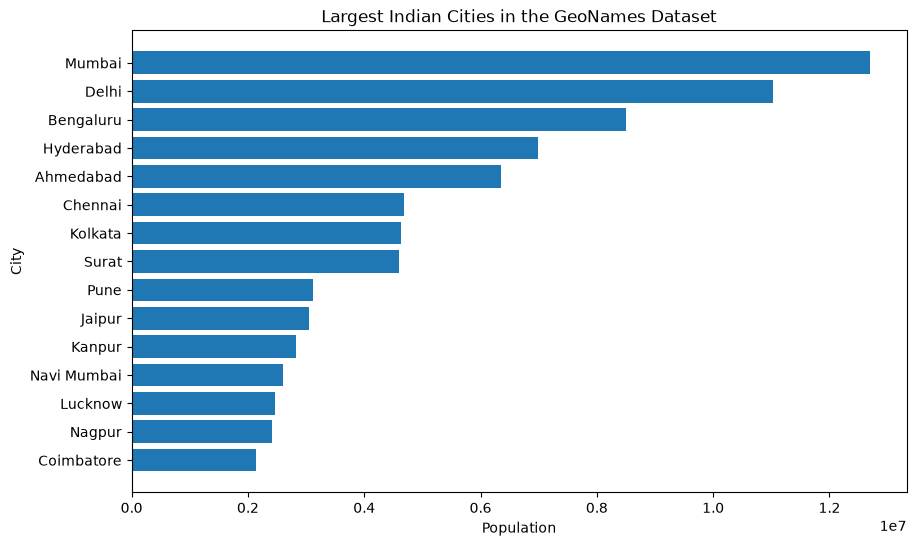

In [9]:
top_indian_cities = (
    india
    .sort_values("population", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_indian_cities["city"],
    top_indian_cities["population"]
)

plt.xlabel("Population")
plt.ylabel("City")
plt.title("Largest Indian Cities in the GeoNames Dataset")

plt.gca().invert_yaxis()

plt.show()